# CISC7204 Assignment 02 - Complete Self-Contained Analysis

## U.S. Nonfarm Employment Recovery by Industry and State, 2019-2023

**Class F, Pair 04:** Wang Di (mc663385) and Zhaowei ([partner ID withheld])

This notebook contains all code required to reproduce the final analysis:

1. Load the included CES, SAE and FRED CSV files
2. Clean and validate the data
3. Calculate peak-to-trough and recovery metrics
4. Produce the national trend, industry comparison, bar chart and state map
5. Generate the two-paragraph visual justification and analysis summary

All code is contained in this notebook. No import from `04_Scripts` is required.

**Inputs**

- `Data/manual_ces.csv`
- `Data/manual_sae.csv`
- `Data/fred_payems.csv`
- `Data/us-states.json`

**Outputs**

- `Results/final_visual.png`
- `Results/visual_justification.md`
- `Results/state_recovery_map.html`
- `Results/data_quality_report.json`
- `Results/analysis_summary.json`


In [1]:
import json
from pathlib import Path

import folium
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from matplotlib.ticker import StrMethodFormatter

# Locate the package root whether this notebook is launched from the root or 03_Notebooks.
candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (p for p in candidates if (p / "Data/manual_ces.csv").exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate 02_Data/raw/manual_ces.csv")

DATA_DIR = PROJECT_ROOT / "Data"
RESULTS_DIR = PROJECT_ROOT / "Results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

START_DATE = pd.Timestamp("2019-01-01")
END_DATE = pd.Timestamp("2023-04-01")
BASELINE_DATE = pd.Timestamp("2019-01-01")
PRE_SHOCK_START = pd.Timestamp("2019-12-01")
PRE_SHOCK_END = pd.Timestamp("2020-03-01")
SHOCK_END = pd.Timestamp("2020-12-01")

STATE_INFO = {
    "Alabama": ("AL", "01"), "Alaska": ("AK", "02"), "Arizona": ("AZ", "04"),
    "Arkansas": ("AR", "05"), "California": ("CA", "06"), "Colorado": ("CO", "08"),
    "Connecticut": ("CT", "09"), "Delaware": ("DE", "10"), "District of Columbia": ("DC", "11"),
    "Florida": ("FL", "12"), "Georgia": ("GA", "13"), "Hawaii": ("HI", "15"),
    "Idaho": ("ID", "16"), "Illinois": ("IL", "17"), "Indiana": ("IN", "18"),
    "Iowa": ("IA", "19"), "Kansas": ("KS", "20"), "Kentucky": ("KY", "21"),
    "Louisiana": ("LA", "22"), "Maine": ("ME", "23"), "Maryland": ("MD", "24"),
    "Massachusetts": ("MA", "25"), "Michigan": ("MI", "26"), "Minnesota": ("MN", "27"),
    "Mississippi": ("MS", "28"), "Missouri": ("MO", "29"), "Montana": ("MT", "30"),
    "Nebraska": ("NE", "31"), "Nevada": ("NV", "32"), "New Hampshire": ("NH", "33"),
    "New Jersey": ("NJ", "34"), "New Mexico": ("NM", "35"), "New York": ("NY", "36"),
    "North Carolina": ("NC", "37"), "North Dakota": ("ND", "38"), "Ohio": ("OH", "39"),
    "Oklahoma": ("OK", "40"), "Oregon": ("OR", "41"), "Pennsylvania": ("PA", "42"),
    "Rhode Island": ("RI", "44"), "South Carolina": ("SC", "45"), "South Dakota": ("SD", "46"),
    "Tennessee": ("TN", "47"), "Texas": ("TX", "48"), "Utah": ("UT", "49"),
    "Vermont": ("VT", "50"), "Virginia": ("VA", "51"), "Washington": ("WA", "53"),
    "West Virginia": ("WV", "54"), "Wisconsin": ("WI", "55"), "Wyoming": ("WY", "56"),
}

print("Project root:", PROJECT_ROOT)
print("Analysis period:", START_DATE.date(), "to", END_DATE.date())
print("Python environment:", __import__("sys").executable)


Project root: C:\Users\dee0306\Desktop\7204 ass02\proposal最終
Analysis period: 2019-01-01 to 2023-04-01
Python environment: D:\Miniconda3\envs\env_311\python.exe


In [2]:
# Load the three included input tables.
ces_raw = pd.read_csv(DATA_DIR / "manual_ces.csv")
sae_raw = pd.read_csv(DATA_DIR / "manual_sae.csv")
fred_raw = pd.read_csv(DATA_DIR / "fred_payems.csv")

print("CES:", ces_raw.shape)
print("SAE:", sae_raw.shape)
print("FRED:", fred_raw.shape)
display(ces_raw.head())
display(sae_raw.head())
display(fred_raw.head())


CES: (624, 4)
SAE: (2652, 4)
FRED: (52, 2)


,date,seriesID,industry,employment_thousands
0,2019-01-01,CEU2000000001,Construction,7069.0
1,2019-01-01,CEU6500000001,Education and health services,23724.0
2,2019-01-01,CEU5500000001,Financial activities,8618.0
3,2019-01-01,CEU9000000001,Government,22378.0
4,2019-01-01,CEU5000000001,Information,2799.0


,date,series_id,state,employment_thousands
0,2019-01-01,SMU01000000000000001,Alabama,2043.2
1,2019-01-01,SMU02000000000000001,Alaska,309.5
2,2019-01-01,SMU04000000000000001,Arizona,2899.7
3,2019-01-01,SMU05000000000000001,Arkansas,1267.0
4,2019-01-01,SMU06000000000000001,California,17143.4


,observation_date,PAYEMS
0,2019-01-01,151001
1,2019-02-01,151225
2,2019-03-01,151468
3,2019-04-01,151668
4,2019-05-01,151855


In [3]:
# Clean and validate the data.
ces = ces_raw.copy()
sae = sae_raw.copy()
fred = fred_raw.copy()

ces["date"] = pd.to_datetime(ces["date"], errors="coerce")
ces["employment_thousands"] = pd.to_numeric(ces["employment_thousands"], errors="coerce")
ces["series_id"] = ces.get("series_id", ces.get("seriesID", "")).astype(str).str.strip()
ces = ces.dropna(subset=["date", "industry", "employment_thousands"])
ces = ces.drop_duplicates(["date", "industry"], keep="last")
ces = ces[(ces["date"] >= START_DATE) & (ces["date"] <= END_DATE)]

sae["date"] = pd.to_datetime(sae["date"], errors="coerce")
sae["employment_thousands"] = pd.to_numeric(sae["employment_thousands"], errors="coerce")
sae["state"] = sae["state"].astype(str).str.strip()
sae = sae[sae["state"].isin(STATE_INFO)]
sae = sae.dropna(subset=["date", "state", "employment_thousands"])
sae = sae.drop_duplicates(["date", "state"], keep="last")
sae = sae[(sae["date"] >= START_DATE) & (sae["date"] <= END_DATE)]
sae["state_abbr"] = sae["state"].map(lambda x: STATE_INFO[x][0])
sae["state_fips"] = sae["state"].map(lambda x: STATE_INFO[x][1])

fred_date_col = "observation_date" if "observation_date" in fred.columns else "date"
fred["date"] = pd.to_datetime(fred[fred_date_col], errors="coerce")
fred["national_total_thousands"] = pd.to_numeric(fred["PAYEMS"], errors="coerce")
fred = fred.dropna(subset=["date", "national_total_thousands"]).drop_duplicates("date")
fred = fred.sort_values("date").reset_index(drop=True)

# The latest common month across all series becomes the analytical endpoint.
common_end = min(
    ces.groupby("industry")["date"].max().min(),
    sae.groupby("state")["date"].max().min(),
    fred["date"].max(),
)
ces = ces[ces["date"] <= common_end].copy()
sae = sae[sae["date"] <= common_end].copy()
fred = fred[fred["date"] <= common_end].copy()

# Use the revised FRED total as the headline national series.
fred_total = fred.set_index("date")["national_total_thousands"]
total_mask = ces["industry"] == "Total nonfarm"
ces.loc[total_mask, "employment_thousands"] = ces.loc[total_mask, "date"].map(fred_total)

sector_sum = (
    ces[ces["industry"] != "Total nonfarm"]
    .groupby("date")["employment_thousands"].sum()
    .rename("sector_sum").reset_index()
)
national_total = ces[ces["industry"] == "Total nonfarm"][["date", "employment_thousands"]]
sector_check = sector_sum.merge(national_total, on="date")
sector_diff_pct = (
    (sector_check["sector_sum"] - sector_check["employment_thousands"]).abs()
    / sector_check["employment_thousands"] * 100
)
fred_check = national_total.merge(fred, on="date")
fred_diff_pct = (
    (fred_check["employment_thousands"] - fred_check["national_total_thousands"]).abs()
    / fred_check["national_total_thousands"] * 100
)

checks = [
    {"check": "All 12 national series available", "passed": ces["industry"].nunique() == 12, "detail": f"{ces['industry'].nunique()} series"},
    {"check": "All 51 state series available", "passed": sae["state"].nunique() == 51, "detail": f"{sae['state'].nunique()} states"},
    {"check": "No duplicate national observations", "passed": not ces.duplicated(["date", "industry"]).any(), "detail": "duplicates removed"},
    {"check": "No duplicate state observations", "passed": not sae.duplicated(["date", "state"]).any(), "detail": "duplicates removed"},
    {"check": "No non-positive employment values", "passed": bool((ces["employment_thousands"] > 0).all() and (sae["employment_thousands"] > 0).all()), "detail": "all values positive"},
    {"check": "Baseline month available", "passed": BASELINE_DATE >= min(ces["date"].min(), sae["date"].min()), "detail": "2019-01"},
    {"check": "State data cover common end month", "passed": (sae["date"] == common_end).sum() == 51, "detail": common_end.strftime("%Y-%m")},
    {"check": "National sector sum agrees with FRED total within 2.5%", "passed": bool(sector_diff_pct.max() <= 2.5), "detail": f"max {sector_diff_pct.max():.3f}%"},
    {"check": "FRED total is the headline national series", "passed": bool(fred_diff_pct.max() < 1e-9), "detail": "exact match"},
]

quality = {
    "analysis_period": {"start": ces["date"].min().strftime("%Y-%m-%d"), "end": common_end.strftime("%Y-%m-%d")},
    "rows": {"ces": len(ces), "sae": len(sae), "fred": len(fred)},
    "coverage": {"national_series": int(ces["industry"].nunique()), "states": int(sae["state"].nunique())},
    "quality_metrics": {
        "national_sector_sum_max_percent": float(sector_diff_pct.max()),
        "fred_national_total_max_percent": float(fred_diff_pct.max()),
    },
    "checks": checks,
}
(RESULTS_DIR / "data_quality_report.json").write_text(json.dumps(quality, indent=2, default=lambda o: o.item() if isinstance(o, np.generic) else str(o)), encoding="utf-8")

display(pd.DataFrame(checks))
print("Common period:", ces["date"].min().date(), "to", common_end.date())


,check,passed,detail
0,All 12 national series available,True,12 series
1,All 51 state series available,True,51 states
2,No duplicate national observations,True,duplicates removed
3,No duplicate state observations,True,duplicates removed
4,No non-positive employment values,True,all values positive
5,Baseline month available,True,2019-01
6,State data cover common end month,True,2023-04
7,National sector sum agrees with FRED total wit...,True,max 2.068%
8,FRED total is the headline national series,True,exact match


Common period: 2019-01-01 to 2023-04-01


In [4]:
# Calculate recovery metrics.
def compute_metrics(df, entity_col, value_col="employment_thousands"):
    rows = []
    for entity, group in df.groupby(entity_col):
        group = group.sort_values("date")
        baseline = group[group["date"] <= BASELINE_DATE].tail(1)
        pre = group[(group["date"] >= PRE_SHOCK_START) & (group["date"] <= PRE_SHOCK_END)]
        if baseline.empty or pre.empty:
            continue
        peak = pre.loc[pre[value_col].idxmax()]
        shock = group[(group["date"] >= peak["date"]) & (group["date"] <= SHOCK_END)]
        trough = shock.loc[shock[value_col].idxmin()]
        latest = group.tail(1).iloc[0]
        later = group[group["date"] > trough["date"]]
        recovered = later[later[value_col] >= peak[value_col]]
        recovery_date = recovered.iloc[0]["date"] if not recovered.empty else pd.NaT
        rows.append({
            entity_col: entity,
            "baseline_thousands": baseline.iloc[0][value_col],
            "pre_shock_peak_date": peak["date"],
            "pre_shock_peak_thousands": peak[value_col],
            "shock_trough_date": trough["date"],
            "shock_trough_thousands": trough[value_col],
            "shock_pct": (trough[value_col] - peak[value_col]) / peak[value_col] * 100,
            "latest_date": latest["date"],
            "latest_employment_thousands": latest[value_col],
            "change_vs_peak_thousands": latest[value_col] - peak[value_col],
            "recovery_pct_vs_peak": (latest[value_col] - peak[value_col]) / peak[value_col] * 100,
            "index_jan2019": latest[value_col] / baseline.iloc[0][value_col] * 100,
            "recovered_by_latest": latest[value_col] >= peak[value_col],
            "recovery_date": recovery_date,
        })
    return pd.DataFrame(rows)

national = ces[ces["industry"] == "Total nonfarm"].copy()
industries = ces[ces["industry"] != "Total nonfarm"].copy()
national_metrics = compute_metrics(national, "industry")
industry_metrics = compute_metrics(industries, "industry")
state_metrics = compute_metrics(sae, "state")
state_metrics = state_metrics.merge(sae[["state", "state_abbr", "state_fips"]].drop_duplicates(), on="state", how="left")

indexed_frames = []
for industry, group in industries.groupby("industry"):
    group = group.sort_values("date").copy()
    base = group[group["date"] <= BASELINE_DATE].tail(1).iloc[0]["employment_thousands"]
    group["index_jan2019"] = group["employment_thousands"] / base * 100
    indexed_frames.append(group)
indexed = pd.concat(indexed_frames, ignore_index=True)

summary = {
    "latest_common_month": common_end.strftime("%Y-%m"),
    "national": national_metrics.iloc[0][["pre_shock_peak_date", "shock_trough_date", "shock_pct", "recovery_pct_vs_peak", "index_jan2019"]].to_dict(),
    "top_industries": industry_metrics.nlargest(3, "recovery_pct_vs_peak")[["industry", "recovery_pct_vs_peak"]].to_dict("records"),
    "weak_industries": industry_metrics.nsmallest(3, "recovery_pct_vs_peak")[["industry", "recovery_pct_vs_peak"]].to_dict("records"),
    "top_states": state_metrics.nlargest(5, "recovery_pct_vs_peak")[["state", "recovery_pct_vs_peak"]].to_dict("records"),
    "weak_states": state_metrics.nsmallest(5, "recovery_pct_vs_peak")[["state", "recovery_pct_vs_peak"]].to_dict("records"),
}
summary["national"]["pre_shock_peak_date"] = str(pd.Timestamp(summary["national"]["pre_shock_peak_date"]).date())
summary["national"]["shock_trough_date"] = str(pd.Timestamp(summary["national"]["shock_trough_date"]).date())

display(national_metrics)


,industry,baseline_thousands,pre_shock_peak_date,pre_shock_peak_thousands,shock_trough_date,shock_trough_thousands,shock_pct,latest_date,latest_employment_thousands,change_vs_peak_thousands,recovery_pct_vs_peak,index_jan2019,recovered_by_latest,recovery_date
0,Total nonfarm,151001.0,2020-01-01,152534.0,2020-04-01,130073.0,-14.725242,2023-04-01,155965.0,3431.0,2.249335,103.287395,True,2022-06-01


In [5]:
# Display the industry and state rankings.
industry_display = industry_metrics.sort_values("recovery_pct_vs_peak", ascending=False)[[
    "industry", "shock_pct", "recovery_pct_vs_peak", "index_jan2019", "change_vs_peak_thousands"
]]
state_display = state_metrics.sort_values("recovery_pct_vs_peak", ascending=False)[[
    "state", "shock_pct", "recovery_pct_vs_peak", "index_jan2019", "change_vs_peak_thousands"
]]
print("Industry recovery ranking")
display(industry_display)
print("Strongest state recoveries")
display(state_display.head(10))
print("Weakest state recoveries")
display(state_display.tail(10).sort_values("recovery_pct_vs_peak"))


Industry recovery ranking


,industry,shock_pct,recovery_pct_vs_peak,index_jan2019,change_vs_peak_thousands
0,Construction,-13.449664,5.691275,111.387749,424.0
9,Professional and business services,-11.293987,5.554268,109.625385,1198.0
4,Information,-10.564350,4.439092,108.431583,129.0
2,Financial activities,-3.269601,3.371422,106.022279,298.0
1,Education and health services,-11.257500,2.189071,106.255269,540.0
6,Manufacturing,-11.355483,0.577133,101.248332,74.0
10,"Trade, transportation, and utilities",-14.943938,0.014015,103.653134,4.0
5,Leisure and hospitality,-47.790458,-0.704140,103.932906,-116.0
3,Government,-11.826004,-0.713452,102.609706,-165.0
8,Other services,-23.643148,-1.848711,100.207792,-109.0


Strongest state recoveries


,state,shock_pct,recovery_pct_vs_peak,index_jan2019,change_vs_peak_thousands
12,Idaho,-10.079231,9.702559,115.115170,74.7
44,Utah,-9.824915,8.344880,112.902802,132.5
43,Texas,-11.618518,6.286648,110.319528,819.1
28,Nevada,-23.692181,6.084802,110.861747,88.4
9,Florida,-14.491694,5.998821,109.602059,549.6
26,Montana,-13.156814,5.500821,109.245484,26.8
33,North Carolina,-12.369623,5.402552,108.565657,250.7
3,Arkansas,-9.797894,4.564666,107.395422,59.4
42,Tennessee,-12.490950,4.224510,108.040463,134.2
2,Arizona,-12.081864,4.116271,108.949202,124.9


Weakest state recoveries


,state,shock_pct,recovery_pct_vs_peak,index_jan2019,change_vs_peak_thousands
11,Hawaii,-23.999403,-5.555556,96.993865,-37.2
45,Vermont,-23.172628,-5.007776,97.571885,-16.1
8,District of Columbia,-11.059850,-3.940150,98.240245,-31.6
39,Rhode Island,-21.553589,-3.264503,100.367272,-16.6
32,New York,-20.951297,-2.770669,100.987861,-275.0
34,North Dakota,-13.205418,-2.731377,99.930427,-12.1
48,West Virginia,-14.838079,-2.331100,99.079581,-16.7
6,Connecticut,-18.270295,-2.290343,100.449344,-39.3
20,Maryland,-14.935994,-2.199099,100.840615,-61.5
18,Louisiana,-14.342092,-2.003197,99.155884,-40.1


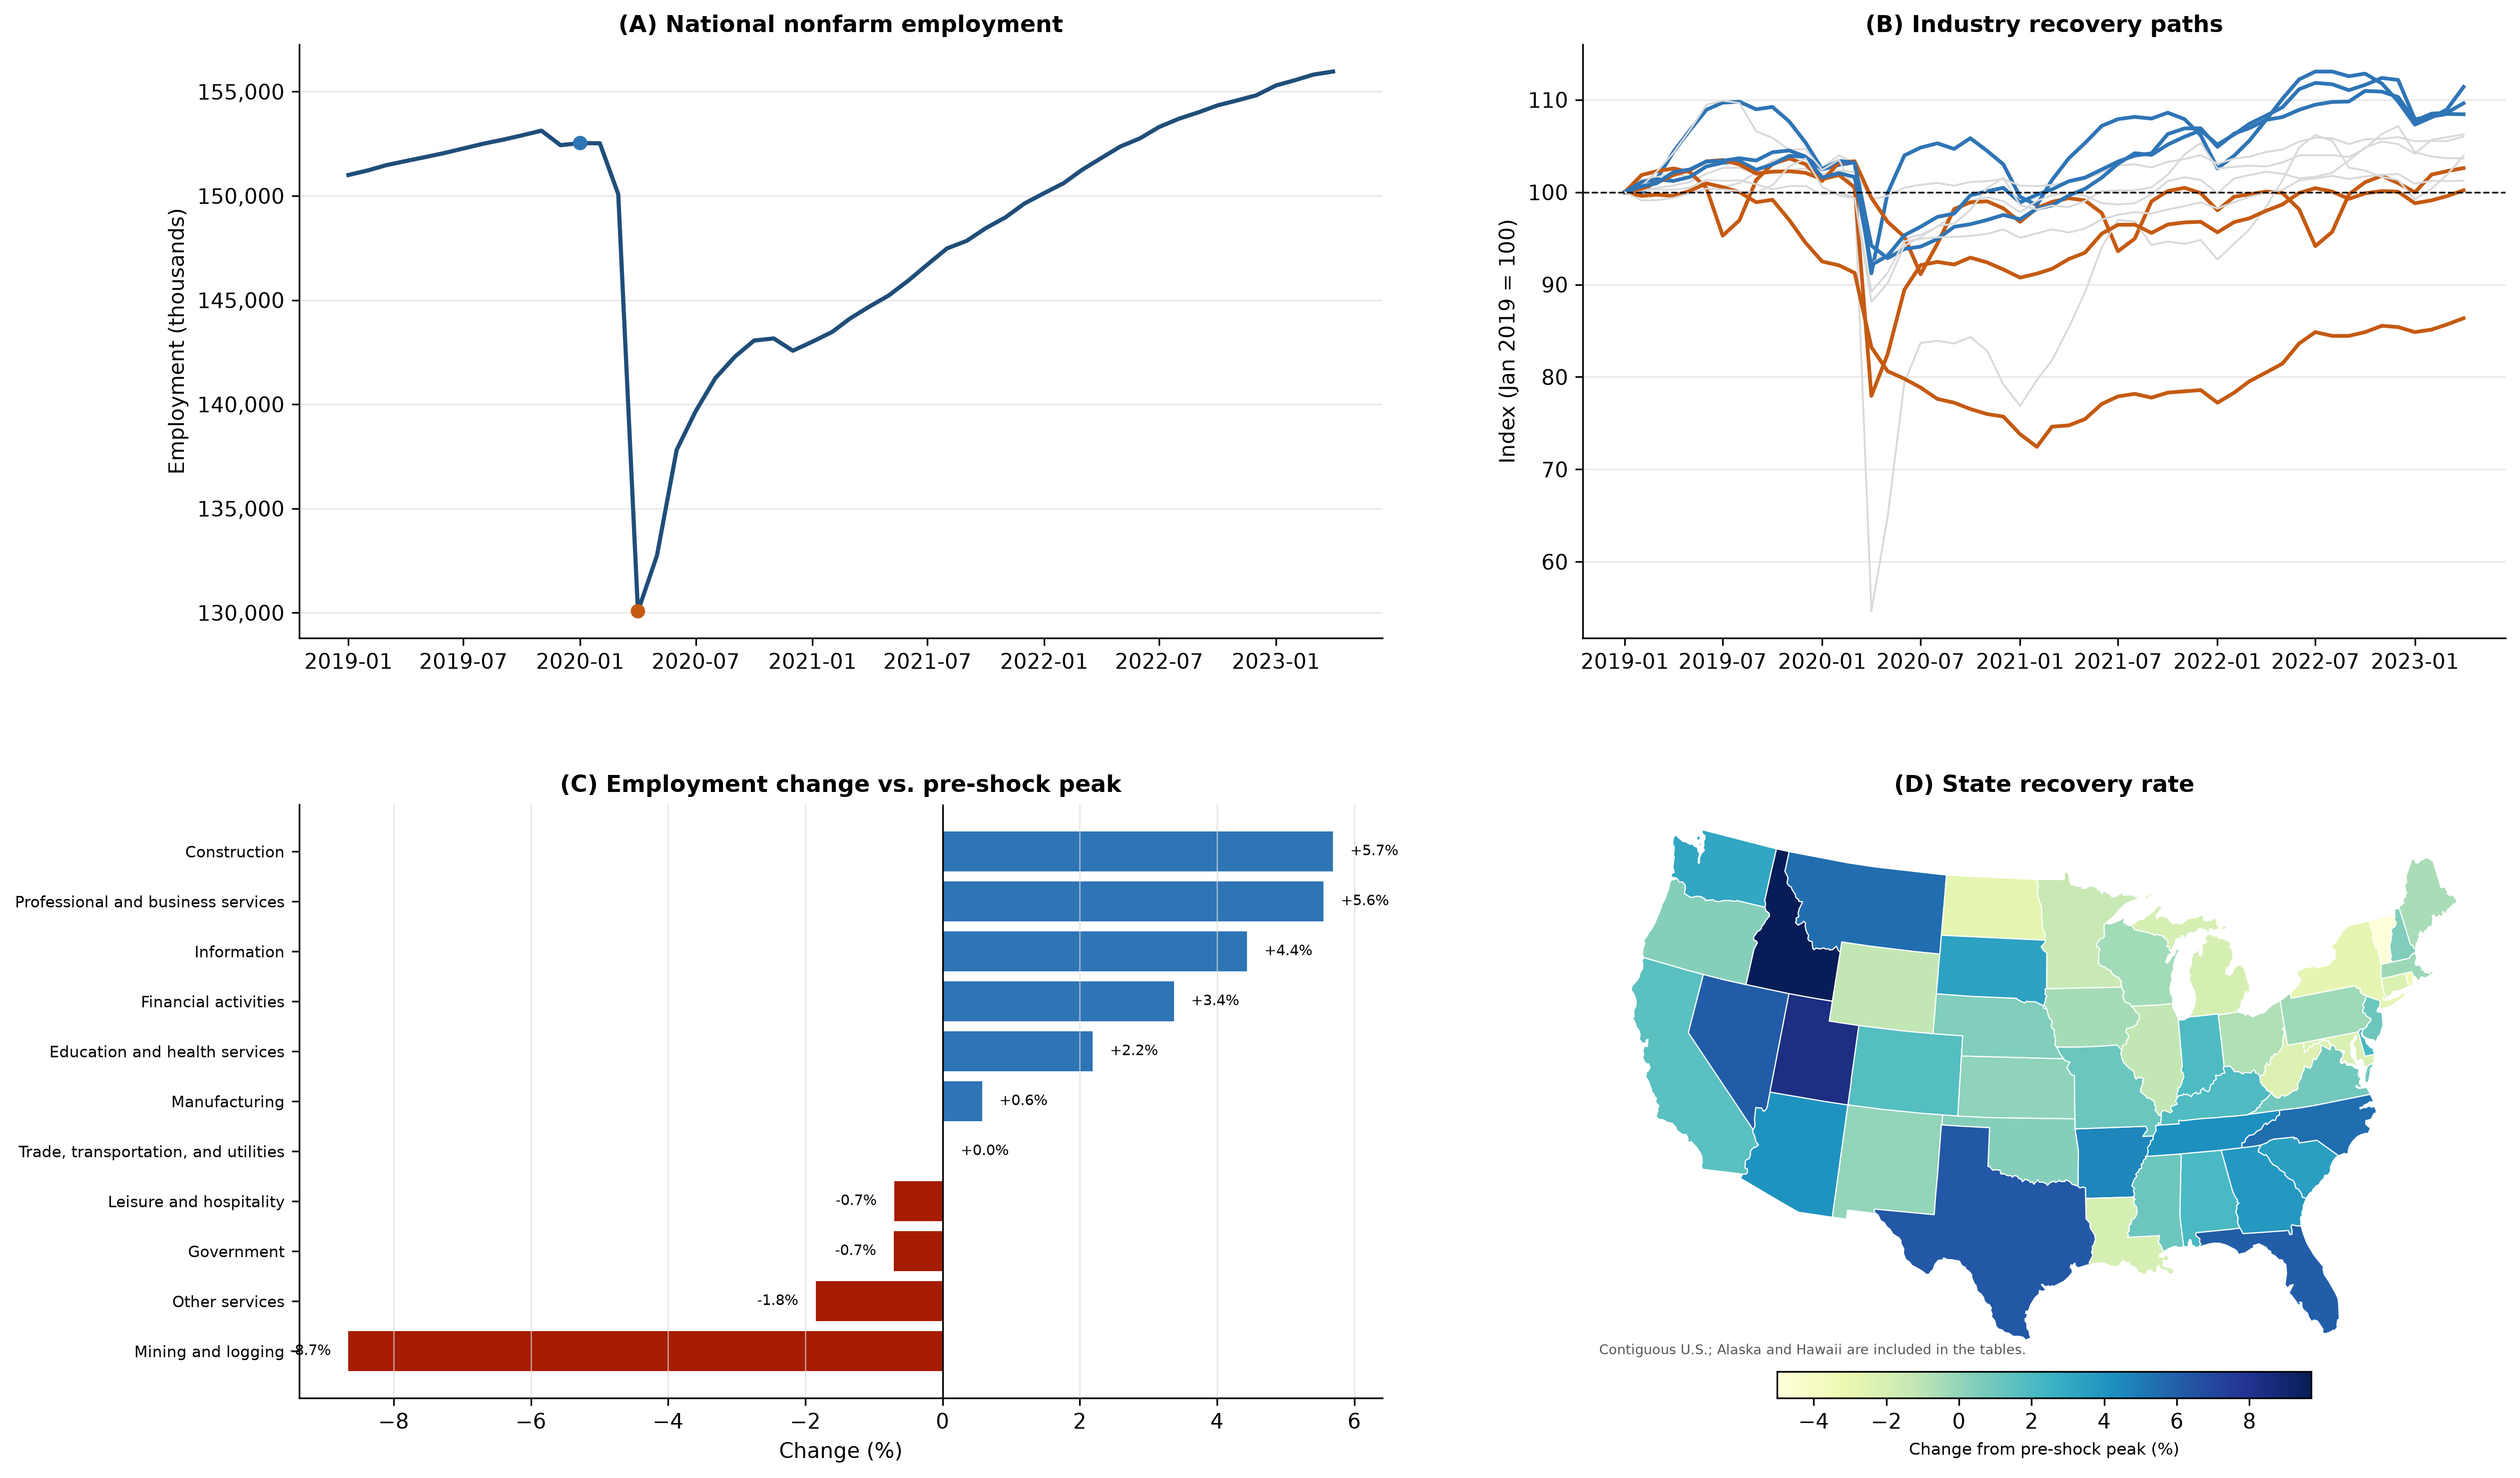

Final visual: C:\Users\dee0306\Desktop\7204 ass02\proposal最終\Results\final_visual.png


In [6]:
# Visualization settings and helper functions.
plt.style.use("default")
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titleweight": "bold",
    "axes.titlesize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})
NAVY, BLUE, ORANGE, RED = "#1F4E79", "#2E75B6", "#C55A11", "#A61C00"
LIGHT_GRAY = "#D9D9D9"

def style_axis(ax):
    ax.grid(axis="y", color=LIGHT_GRAY, linewidth=0.6, alpha=0.7)

def draw_national(ax):
    m = national_metrics.iloc[0]
    ax.plot(national["date"], national["employment_thousands"], color=NAVY, linewidth=2)
    ax.scatter([m["pre_shock_peak_date"], m["shock_trough_date"]],
               [m["pre_shock_peak_thousands"], m["shock_trough_thousands"]],
               color=[BLUE, ORANGE], s=35, zorder=5)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.set_title("(A) National nonfarm employment")
    ax.set_ylabel("Employment (thousands)")
    style_axis(ax)

def draw_industry_index(ax, show_legend=True):
    ranked = industry_metrics.sort_values("recovery_pct_vs_peak", ascending=False)
    strongest, weakest = set(ranked.head(3)["industry"]), set(ranked.tail(3)["industry"])
    for industry, group in indexed.groupby("industry"):
        if industry in strongest:
            ax.plot(group["date"], group["index_jan2019"], color=BLUE, linewidth=1.8, label=industry)
        elif industry in weakest:
            ax.plot(group["date"], group["index_jan2019"], color=ORANGE, linewidth=1.8, label=industry)
        else:
            ax.plot(group["date"], group["index_jan2019"], color=LIGHT_GRAY, linewidth=0.9)
    ax.axhline(100, color="black", linewidth=0.8, linestyle="--")
    ax.set_title("(B) Industry recovery paths")
    ax.set_ylabel("Index (Jan 2019 = 100)")
    style_axis(ax)
    if show_legend:
        ax.legend(frameon=False, fontsize=7, loc="upper left")

def draw_industry_bar(ax):
    data = industry_metrics.sort_values("recovery_pct_vs_peak")
    colors = [BLUE if x >= 0 else RED for x in data["recovery_pct_vs_peak"]]
    ax.barh(data["industry"], data["recovery_pct_vs_peak"], color=colors)
    ax.axvline(0, color="black", linewidth=0.8)
    for i, value in enumerate(data["recovery_pct_vs_peak"]):
        ax.text(value + (0.25 if value >= 0 else -0.25), i, f"{value:+.1f}%",
                va="center", ha="left" if value >= 0 else "right", fontsize=7)
    ax.set_title("(C) Employment change vs. pre-shock peak")
    ax.set_xlabel("Change (%)")
    ax.tick_params(axis="y", labelsize=7.5)
    ax.grid(axis="x", color=LIGHT_GRAY, linewidth=0.6, alpha=0.7)

geo = gpd.read_file(DATA_DIR / "us-states.json")
geo["id"] = geo["id"].astype(str).str.upper()

def draw_state_map(ax):
    merged = geo.merge(state_metrics[["state_abbr", "recovery_pct_vs_peak", "state"]],
                       left_on="id", right_on="state_abbr", how="left")
    merged = merged[~merged["id"].isin(["AK", "HI"])].to_crs(5070)
    vmin, vmax = merged["recovery_pct_vs_peak"].min(), merged["recovery_pct_vs_peak"].max()
    merged.plot(column="recovery_pct_vs_peak", cmap="YlGnBu", linewidth=0.55,
                edgecolor="white", vmin=vmin, vmax=vmax, ax=ax)
    ax.set_axis_off()
    ax.set_title("(D) State recovery rate")
    sm = plt.cm.ScalarMappable(cmap="YlGnBu", norm=plt.Normalize(vmin=vmin, vmax=vmax))
    cbar = plt.colorbar(sm, ax=ax, orientation="horizontal", fraction=0.045, pad=0.01)
    cbar.set_label("Change from pre-shock peak (%)", fontsize=8)
    ax.text(0.01, 0.02, "Contiguous U.S.; Alaska and Hawaii are included in the tables.",
            transform=ax.transAxes, fontsize=6.5, color="#555555")

def save_figure(fig, name):
    path = RESULTS_DIR / name
    fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    return path


fig = plt.figure(figsize=(16, 10.5))
gs = fig.add_gridspec(2, 2, width_ratios=[1.08, 0.92], hspace=0.28, wspace=0.2)
draw_national(fig.add_subplot(gs[0, 0]))
draw_industry_index(fig.add_subplot(gs[0, 1]), show_legend=False)
draw_industry_bar(fig.add_subplot(gs[1, 0]))
draw_state_map(fig.add_subplot(gs[1, 1]))
fig.subplots_adjust(top=0.93, bottom=0.07, left=0.06, right=0.98)
final_visual = save_figure(fig, "final_visual.png")
display(Image(filename=str(final_visual), width=1200))
print("Final visual:", final_visual)


In [7]:
# Create the interactive state map.
geo_json = json.loads((DATA_DIR / "us-states.json").read_text(encoding="utf-8"))
interactive = folium.Map(location=[38.2, -96.0], zoom_start=4, tiles="OpenStreetMap")
folium.Choropleth(
    geo_data=geo_json,
    data=state_metrics,
    columns=["state_abbr", "recovery_pct_vs_peak"],
    key_on="feature.id",
    fill_color="YlGnBu",
    fill_opacity=0.8,
    line_opacity=0.35,
    legend_name="Change from pre-shock peak (%)",
).add_to(interactive)
folium.LayerControl().add_to(interactive)
interactive_path = RESULTS_DIR / "state_recovery_map.html"
interactive.save(str(interactive_path))
print("Interactive map:", interactive_path)


Interactive map: C:\Users\dee0306\Desktop\7204 ass02\proposal最終\Results\state_recovery_map.html


In [8]:
# Generate the two-paragraph visual justification and project summary.
national_m = national_metrics.iloc[0]
top_i = industry_metrics.nlargest(3, "recovery_pct_vs_peak")
weak_i = industry_metrics.nsmallest(3, "recovery_pct_vs_peak")
top_s = state_metrics.nlargest(5, "recovery_pct_vs_peak")
weak_s = state_metrics.nsmallest(5, "recovery_pct_vs_peak")

justification = (
    f"The national series reached its pre-shock peak in {pd.Timestamp(national_m['pre_shock_peak_date']):%Y-%m} "
    f"and fell {abs(national_m['shock_pct']):.1f}% by {pd.Timestamp(national_m['shock_trough_date']):%Y-%m}. "
    f"By {common_end:%Y-%m}, total nonfarm employment was {national_m['recovery_pct_vs_peak']:+.1f}% relative to that peak. "
    f"The strongest industry recoveries were {', '.join(f'{r.industry} ({r.recovery_pct_vs_peak:+.1f}%)' for r in top_i.itertuples())}. "
    f"The weakest were {', '.join(f'{r.industry} ({r.recovery_pct_vs_peak:+.1f}%)' for r in weak_i.itertuples())}.\n\n"
    f"At the state level, the strongest recoveries were {', '.join(r.state for r in top_s.itertuples())}, "
    f"while the weakest were {', '.join(r.state for r in weak_s.itertuples())}. "
    "Taken together, the national trend, industry rankings and state map show that recovery was uneven rather than uniform. "
    "These results are descriptive: payroll employment counts jobs rather than individual workers, the series are seasonally adjusted and subject to revision, "
    "and the analysis does not identify the causal effect of any specific policy."
)
(RESULTS_DIR / "visual_justification.md").write_text(justification, encoding="utf-8")

display(Markdown(justification))


The national series reached its pre-shock peak in 2020-01 and fell 14.7% by 2020-04. By 2023-04, total nonfarm employment was +2.2% relative to that peak. The strongest industry recoveries were Construction (+5.7%), Professional and business services (+5.6%), Information (+4.4%). The weakest were Mining and logging (-8.7%), Other services (-1.8%), Government (-0.7%).

At the state level, the strongest recoveries were Idaho, Utah, Texas, Nevada, Florida, while the weakest were Hawaii, Vermont, District of Columbia, Rhode Island, New York. Taken together, the national trend, industry rankings and state map show that recovery was uneven rather than uniform. These results are descriptive: payroll employment counts jobs rather than individual workers, the series are seasonally adjusted and subject to revision, and the analysis does not identify the causal effect of any specific policy.

## Interpretation limits

- Payroll employment measures jobs rather than individual workers.
- Data are seasonally adjusted and subject to benchmark revisions.
- The analysis describes recovery differences and does not estimate causal effects.
- The static map displays the contiguous United States; Alaska and Hawaii remain in all analysis tables.
- All nine data-quality checks must pass before the outputs are used in the submission.
